# HW04 分析报告：降维、PCA 与 UMAP

姓名：董留鑫　学号：38720260158058　GitHub：dongliuxin0209

## 任务 1：降维目的与拟合范围

| 目的 | 需要的输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 2D/3D 坐标、可追踪的样本编号 | 结构可读且对参数/种子不过度敏感 |
| 去噪 | 低维表示或重建数据 | 重复测量、重建误差或下游验证显示噪声降低且信号保留 |
| 压缩特征 | 更少坐标、解释率/重建误差 | 在可接受的信息损失下减少维度和成本 |
| 发现样本结构 | 候选邻域、分组或梯度 | 在合理参数下稳定，并由独立数据/信息验证 |
| 建模输入 | 训练拟合的变换及分类器 | 无泄露交叉验证与独立测试表现 |

描述当前 72 例：表达矩阵 → 全部样本按探针标准化 → PCA/UMAP → 拟合后按诊断着色。这只能描述当前样本。预测新样本：先划分数据 → 每个训练折内拟合标准化、PCA 与分类器 → 用训练折变换验证折并预测 → 固定方案后评估未参与选择的测试集。

PCA 虽不使用标签，但全数据 PCA 仍会使用验证样本的特征分布来估计均值、尺度和协方差/主轴。验证数据因而参与了表示的选择，交叉验证不再模拟完全未见数据，分数可能偏乐观。所有拟合变换应放在 Pipeline 内随每折重新拟合。

## 任务 2：PCA 对照

数据为 72 个样本、7,129 个探针；ALL 47 例、AML 25 例。没有将三个元数据列输入 PCA。标准化后各列均值最大绝对值为 `5.98e-16`，总体标准差与 1 的最大绝对偏差为 `3.33e-16`。

标准化 PCA 的 PC1 解释率为 **14.92%**，PC2 为 **9.45%**，两者累计 **24.37%**；累计解释率达到 80% 需要 **37 个主成分**。PC1 的 `components_.T` 方向权重绝对值前五项如下：

| 探针 | PC1 权重 |
|---|---:|
| X92518_s_at | 0.02879 |
| X95190_at | -0.02818 |
| X98253_at | 0.02793 |
| X82895_at | 0.02787 |
| Y09616_at | 0.02776 |

仅中心化、不标准化的原尺度 PCA：PC1 为 **17.43%**、PC2 为 **10.34%**、前两轴合计 **27.77%**。PC1 前五个绝对权重探针为 `M25079_s_at` (0.35239)、`hum_alu_at` (0.31355)、`HG1428-HT1428_s_at` (0.23487)、`L06499_at` (0.21045)、`J04617_s_at` (0.19625)，与标准化结果不同。原尺度 PCA 更受原始尺度/方差较大的探针影响；标准化让每列以自身变异尺度参与，但可能放大低变异噪声。标准化不是微阵列上游归一化的替代品。

PC1 是使当前中心化输入投影方差最大的单位方向；每个样本得分是所有标准化探针按方向权重加权的和。它不等同于最能区分 ALL/AML 的方向，也不代表单一基因或机制。PCA 方向符号整体翻转只会同时翻转得分和权重，不改变几何结构与解释率。72 行中心化矩阵的秩最多为 71，故至多有 71 个非零主成分。



样本编号、诊断与 PC 坐标对应表见 `.tmp/dimension-reduction/student-results/pca-sample-coordinates.csv`。UMAP 可复现实验代码保存在同目录的 `run_umap.py`；运行成功后会导出四组坐标、并排图及稳定性指标。

## 任务 3：UMAP 稳定性

拟运行基线参数：`n_neighbors=15`、`min_dist=0.1`、`metric='euclidean'`、`random_state=42`、`n_jobs=1`；对照依次仅把 `n_neighbors` 改为 5、`min_dist` 改为 0.5、随机种子改为 7。所有嵌入应使用同一标准化矩阵并按 `sample_id` 保留坐标。

最初导入停顿经调用栈检查定位到 Numba 缓存目录的临时文件写入；将该进程缓存与临时目录置于课程指定的可写结果目录后，四组实验均成功运行。UMAP 使用默认 n_epochs=None（本数据默认500次）。

| 设置（其余与基线相同） | 与基线10近邻平均重叠率 | 二维两两距离Spearman相关 | 高维到二维trustworthiness（k=10） |
|---|---:|---:|---:|
| 基线 | 1.0000 | 1.0000 | 0.7931 |
| n_neighbors=5 | 0.6208 | 0.8397 | 0.7783 |
| min_dist=0.5 | 0.6764 | 0.8657 | 0.7963 |
| seed=7 | 0.6764 | 0.8805 | 0.7944 |

重叠率定义：每个样本在嵌入中排除自身后的10个最近邻，与基线邻域交集大小除以10，再对72例平均。Trustworthiness衡量低维引入错误近邻的程度，均不是临床准确率。二维距离相关用于比较布局，不证明高维全局距离得以保留。

图上有AML富集区域，但ALL/AML仍存在混合。小邻居数形成更分散的局部布局，min_dist=0.5使点更铺开，改变种子也改变朝向与位置。平均保留约6—7个基线近邻，说明部分局部关系重现，不能称完全稳定。

样本追踪例：G001在四组布局的10近邻共有G003、G004、G007、G008、G009、G027、G049；G038共有G028、G032、G033、G036、G037、G051、G053。相反，G010仅有G011、G023、G071三个共同近邻，表明稳定性并非各样本相同。这是布局间一致性证据，不等于这些关系在原始高维中都准确保留。



| 比较项 | PCA | UMAP |
|---|---|---|
| 线性/非线性 | 线性正交投影 | 非线性嵌入 |
| 主要保留 | 投影方差 | 高维局部邻域 |
| 轴含义 | 探针加权方向，可追踪loading | 无固定生物含义 |
| 方差解释率 | 可以报告 | 无PCA式解释率 |
| 局部/全局距离 | 投影可能丢失两者 | 侧重局部，岛间距离不能直接解释 |
| 参数/随机性 | 成分数、尺度；full SVD确定性 | 邻居数、min_dist、度量和种子均影响 |
| 预测防泄露 | 各训练折拟合标准化与PCA | 各训练折拟合标准化与UMAP，再transform验证折 |

UMAP常用于单细胞和复杂表型的探索展示，因为它能用二维呈现非线性局部关系；细胞多并不代表独立患者更多。三条判断：①重复出现的局部邻域和富集区可提出假设，但不能证明机制；②岛屿数量、间距、方向和面积不能直接对应真实亚型数或差异大小；③本数据缺患者映射与批次字段，不能排除批次，也不能仅凭图报告新患者预测性能。

## 任务 4：主张—证据—推理—边界

1. **主张：**二维图分开本身不能证明疾病机制，也不能证明可预测新患者。
2. **证据：**标准化 PCA 的 PC1 解释率为 14.92%、PC2 为 9.45%，合计仅 24.37%；PC1 是无标签的最大方差方向，而非疾病判别方向。
3. **推理：**UMAP仅将邻居数15改为5后，与基线的10近邻平均重叠率为0.6208，说明局部布局对参数有敏感性；图形只能提出结构假设，不能把视觉分离直接升级为机制或预测证据。
4. **边界与后续验证：**可在预先定义的独立患者队列中按患者/中心分组验证，并在训练折内完成预处理，随后检验候选表达模式及其跨队列可重复性；当前样本缺少患者映射和批次字段，不能据此作机制、亚型或临床泛化结论。

## 可选验证：训练集内交叉验证

原始训练 38 例（ALL 27、AML 11），`StratifiedKFold(3, shuffle=True, random_state=42)`，标准化及 PCA 都在 Pipeline 折内拟合：

| 方法 | 三折 balanced accuracy | 均值 |
|---|---|---:|
| StandardScaler + 1-NN | 0.819、0.875、0.833 | 0.843 |
| StandardScaler + PCA(10) + 1-NN | 0.694、0.764、0.833 | 0.764 |

这只是 38 例训练集上的内部比较，不能据此在测试集选参或宣称临床预测性能。

## 运行记录与 AI 使用

- Python 3.11.17；NumPy 2.2.3、Pandas 2.2.3、scikit-learn 1.8.0、Matplotlib 3.10.8。
- 全数据描述性标准化及 PCA 的拟合范围为当前 72 例；交叉验证的拟合范围为每折训练数据。
- UMAP 0.5.12；四组参数如任务3所列，n_epochs=None，其余默认；Numba 0.68.1、llvmlite 0.50.0。坐标及图见本地结果目录和Notebook内嵌输出。
- 使用 AI 协助阅读要求、定位运行环境问题和组织代码/解释；数值与图来自本地实际执行。本人提交前应检查输出、理解结论并确认最终文字；不宣称已经独立核验。

## 三道课后题

1. PC1是投影方差最大的单位线性方向，本次解释14.92%；X92518_s_at的方向权重为+0.02879，表示它参与多探针加权和，不能直接解释为致病基因。整体翻转主轴符号不改变结果。
2. 标准化让各探针以自身标准差计量，改变大方差探针对主轴的支配作用。本次原尺度前两轴27.77%、标准化24.37%，高权重探针也不同；解释率不能单独用来比较优劣。标准化可能放大低变异噪声，且不替代上游归一化；含负值矩阵不直接取log/log1p。
3. UMAP支持局部邻域和候选结构探索，不能证明亚型数、机制或临床预测。仅改seed为7时，10近邻平均重叠率0.6764，图形布局变化但部分局部关系保留；应报告所有参数对照而非挑图。

## 可复现代码与实际运行输出

以下代码由讲义8.1/8.2扩展原尺度PCA、累计曲线、三个单因素UMAP对照、邻域检查和折内Pipeline验证。可从仓库内任意目录运行，缓存与可再生成图片只写入指定.tmp目录。

In [1]:
from __future__ import annotations

import json
import platform
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'assignments/hw04').is_dir())
DATA = ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv"
OUT = ROOT / ".tmp/dimension-reduction/student-results"
OUT.mkdir(parents=True, exist_ok=True)


def main():
    df = pd.read_csv(DATA)
    X = df.drop(columns=["sample_id", "original_split", "diagnosis"])
    y = df["diagnosis"].to_numpy()
    Z = StandardScaler().fit_transform(X)
    pca = PCA(svd_solver="full").fit(Z)
    scores = pca.transform(Z)
    raw_pca = PCA(svd_solver="full").fit(X)
    loadings = pd.Series(pca.components_[0], index=X.columns)
    raw_loadings = pd.Series(raw_pca.components_[0], index=X.columns)
    top5 = loadings.loc[loadings.abs().nlargest(5).index]
    raw_top5 = raw_loadings.loc[raw_loadings.abs().nlargest(5).index]
    evr = pca.explained_variance_ratio_

    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.plot(np.arange(1, len(evr) + 1), np.cumsum(evr), lw=1.2)
    ax.set(xlabel="Number of components", ylabel="Cumulative explained variance",
           title="PCA cumulative explained variance", ylim=(0, 1.02))
    ax.axhline(.8, color="gray", ls="--", lw=1)
    fig.tight_layout()
    fig.savefig(OUT / "pca-cumulative-variance.png", dpi=180)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.5, 5))
    for label, color in [("ALL", "#387ca3"), ("AML", "#d57839")]:
        mask = y == label
        ax.scatter(scores[mask, 0], scores[mask, 1], c=color, s=42, label=label,
                   edgecolors="white", linewidths=.35)
    ax.set(xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})",
           title="Standardized PCA: all samples")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT / "pca-standardized.png", dpi=180)
    plt.close(fig)

    train = df["original_split"].eq("train").to_numpy()
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    methods = {
        "StandardScaler + 1-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
        "StandardScaler + PCA(10) + 1-NN": make_pipeline(
            StandardScaler(), PCA(n_components=10, svd_solver="full"), KNeighborsClassifier(n_neighbors=1)
        ),
    }
    cv_results = {}
    for name, model in methods.items():
        values = cross_val_score(model, X.to_numpy()[train], y[train], cv=cv,
                                 scoring="balanced_accuracy")
        cv_results[name] = {"fold_scores": values.tolist(), "mean": float(values.mean())}

    result = {
        "shape": list(X.shape),
        "class_counts": df["diagnosis"].value_counts().to_dict(),
        "train_class_counts": df.loc[train, "diagnosis"].value_counts().to_dict(),
        "test_class_counts": df.loc[~train, "diagnosis"].value_counts().to_dict(),
        "zscore_max_abs_mean": float(np.abs(Z.mean(0)).max()),
        "zscore_max_abs_std_error": float(np.abs(Z.std(0, ddof=0) - 1).max()),
        "standardized_pca": {
            "evr": evr.tolist(), "pc1_pc2": float(evr[:2].sum()),
            "components_80_percent": int(np.searchsorted(np.cumsum(evr), .8) + 1),
            "top5_pc1_loadings": top5.to_dict(),
        },
        "raw_scale_pca": {
            "evr": raw_pca.explained_variance_ratio_.tolist(),
            "pc1_pc2": float(raw_pca.explained_variance_ratio_[:2].sum()),
            "top5_pc1_loadings": raw_top5.to_dict(),
        },
        "training_only_cv": cv_results,
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "sklearn": __import__("sklearn").__version__,
                     "matplotlib": matplotlib.__version__},
    }
    (OUT / "pca-cv-results.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    pd.DataFrame({"sample_id": df.sample_id, "diagnosis": y,
                  "PC1": scores[:, 0], "PC2": scores[:, 1]}).to_csv(
                      OUT / "pca-sample-coordinates.csv", index=False)
    print(json.dumps(result, indent=2))


main()


{
  "shape": [
    72,
    7129
  ],
  "class_counts": {
    "ALL": 47,
    "AML": 25
  },
  "train_class_counts": {
    "ALL": 27,
    "AML": 11
  },
  "test_class_counts": {
    "ALL": 20,
    "AML": 14
  },
  "zscore_max_abs_mean": 5.982868521591122e-16,
  "zscore_max_abs_std_error": 3.3306690738754696e-16,
  "standardized_pca": {
    "evr": [
      0.14921586325599698,
      0.09446172774145271,
      0.04670230659525601,
      0.040354089651858376,
      0.0342798321494741,
      0.03188398416249145,
      0.02706996675997881,
      0.02419888419343441,
      0.022107592542469738,
      0.021499151568193747,
      0.018755613969374894,
      0.0182145650560793,
      0.016755372582501458,
      0.015651784818328678,
      0.015395209559978874,
      0.014303842278879913,
      0.013646687877849527,
      0.012609125683537248,
      0.012455742220807918,
      0.011780976355806964,
      0.01169634599597252,
      0.01135459174139759,
      0.010850625690217601,
      0.01067129908

In [2]:
from __future__ import annotations

from pathlib import Path
import os
import tempfile

# Keep runtime cache in the course-designated, writable results directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'assignments/hw04').is_dir())
OUT = ROOT / ".tmp/dimension-reduction/student-results"
OUT.mkdir(parents=True, exist_ok=True)
os.environ["NUMBA_CACHE_DIR"] = str(OUT / "numba-cache")
tempfile.tempdir = str(OUT)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from umap import UMAP


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'assignments/hw04').is_dir())
DATA = ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv"
OUT = ROOT / ".tmp/dimension-reduction/student-results"
OUT.mkdir(parents=True, exist_ok=True)


def neighbor_sets(coords, k=10):
    indices = NearestNeighbors(n_neighbors=k + 1).fit(coords).kneighbors(coords, return_distance=False)
    return [set(row[1:]) for row in indices]


def main():
    df = pd.read_csv(DATA)
    X = df.drop(columns=["sample_id", "original_split", "diagnosis"])
    labels = df["diagnosis"].to_numpy()
    Z = StandardScaler().fit_transform(X)
    settings = {
        "baseline": dict(n_neighbors=15, min_dist=.1, random_state=42),
        "neighbors5": dict(n_neighbors=5, min_dist=.1, random_state=42),
        "min_dist05": dict(n_neighbors=15, min_dist=.5, random_state=42),
        "seed7": dict(n_neighbors=15, min_dist=.1, random_state=7),
    }
    embeddings = {}
    for name, params in settings.items():
        print(f"Fitting {name}: {params}", flush=True)
        model = UMAP(n_components=2, metric="euclidean", n_jobs=1, **params)
        embeddings[name] = model.fit_transform(Z)
        print(f"Completed {name}", flush=True)

    rows = []
    for name, coords in embeddings.items():
        for i, sample_id in enumerate(df["sample_id"]):
            rows.append({"setting": name, "sample_id": sample_id, "diagnosis": labels[i],
                         "UMAP1": coords[i, 0], "UMAP2": coords[i, 1]})
    pd.DataFrame(rows).to_csv(OUT / "umap-sample-coordinates.csv", index=False)

    base = embeddings["baseline"]
    base_sets = neighbor_sets(base)
    stability = []
    for name, coords in embeddings.items():
        current = neighbor_sets(coords)
        overlap = np.mean([len(a & b) / 10 for a, b in zip(base_sets, current)])
        stability.append({
            "setting": name,
            "mean_10_neighbor_overlap_vs_baseline": float(overlap),
            "spearman_pairwise_distance_vs_baseline": float(spearmanr(pdist(base), pdist(coords)).statistic),
            "trustworthiness_k10": float(trustworthiness(Z, coords, n_neighbors=10)),
        })
    pd.DataFrame(stability).to_csv(OUT / "umap-stability.csv", index=False)

    pca_scores = PCA(svd_solver="full").fit_transform(Z)
    pca_model = PCA(svd_solver="full").fit(Z)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    for ax, coords, title in [(axes[0], pca_scores, "PCA"),
                              (axes[1], embeddings["baseline"], "UMAP baseline")]:
        for label, color in [("ALL", "#387ca3"), ("AML", "#d57839")]:
            mask = labels == label
            ax.scatter(coords[mask, 0], coords[mask, 1], c=color, s=36,
                       label=label, edgecolors="white", linewidths=.3)
        ax.set(title=title, xlabel=(f"PC1 ({pca_model.explained_variance_ratio_[0]:.1%})" if title == "PCA" else "UMAP1"),
               ylabel=(f"PC2 ({pca_model.explained_variance_ratio_[1]:.1%})" if title == "PCA" else "UMAP2"))
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT / "pca-umap-baseline.png", dpi=180)
    plt.close(fig)

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for ax, (name, coords) in zip(axes.flat, embeddings.items()):
        for label, color in [("ALL", "#387ca3"), ("AML", "#d57839")]:
            mask = labels == label
            ax.scatter(coords[mask, 0], coords[mask, 1], c=color, s=30,
                       label=label, edgecolors="white", linewidths=.3)
        params = settings[name]
        ax.set(title=f"{name}: n_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}, seed={params['random_state']}",
               xlabel="UMAP1", ylabel="UMAP2")
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT / "umap-parameter-checks.png", dpi=180)
    plt.close(fig)


main()


Fitting baseline: {'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 42}


Completed baseline


Fitting neighbors5: {'n_neighbors': 5, 'min_dist': 0.1, 'random_state': 42}


Completed neighbors5


Fitting min_dist05: {'n_neighbors': 15, 'min_dist': 0.5, 'random_state': 42}


Completed min_dist05


Fitting seed7: {'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 7}


Completed seed7


numpy 2.2.3
pandas 2.2.3
scipy 1.16.3
scikit-learn 1.8.0
matplotlib 3.10.8
umap-learn 0.5.12
numba 0.68.1
llvmlite 0.50.0
pynndescent 0.7.0
threadpoolctl 3.6.0
nbformat 5.11.1
nbclient 0.11.0


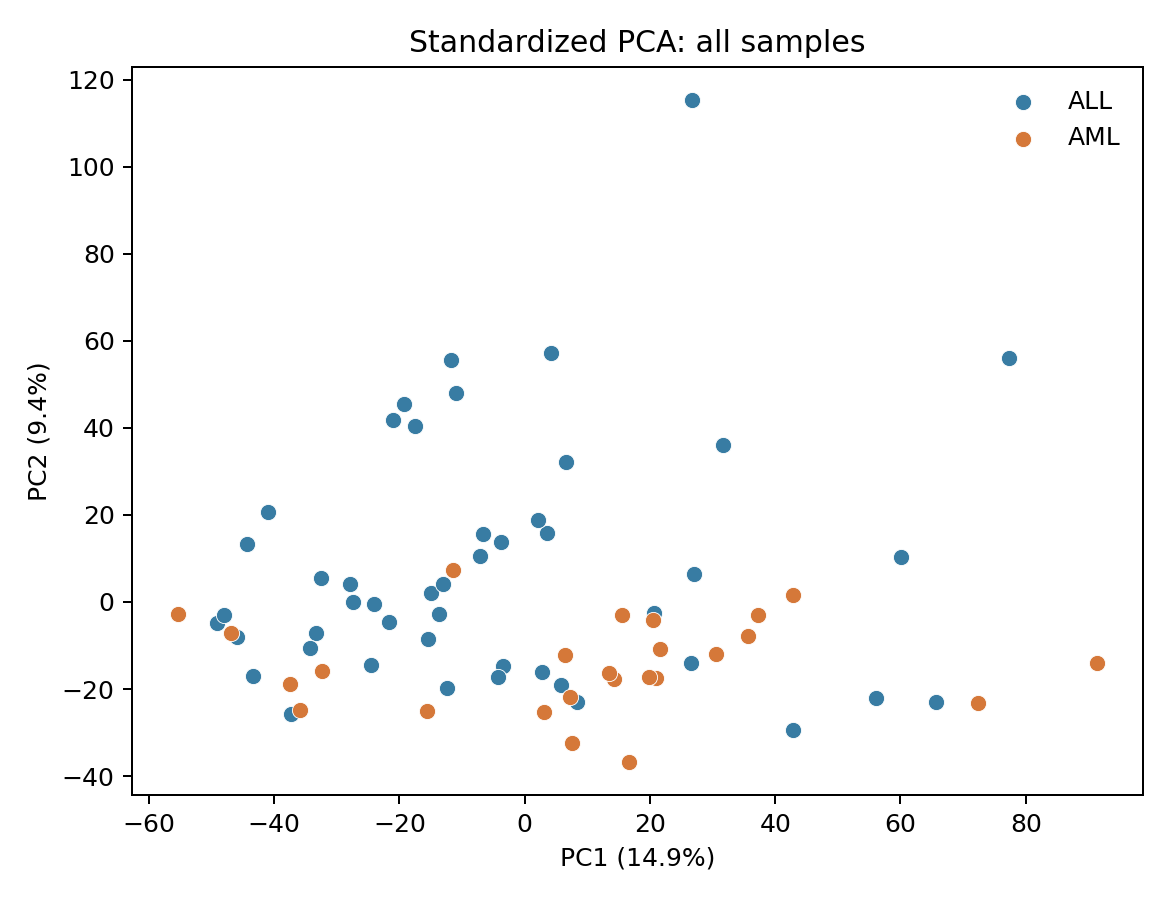

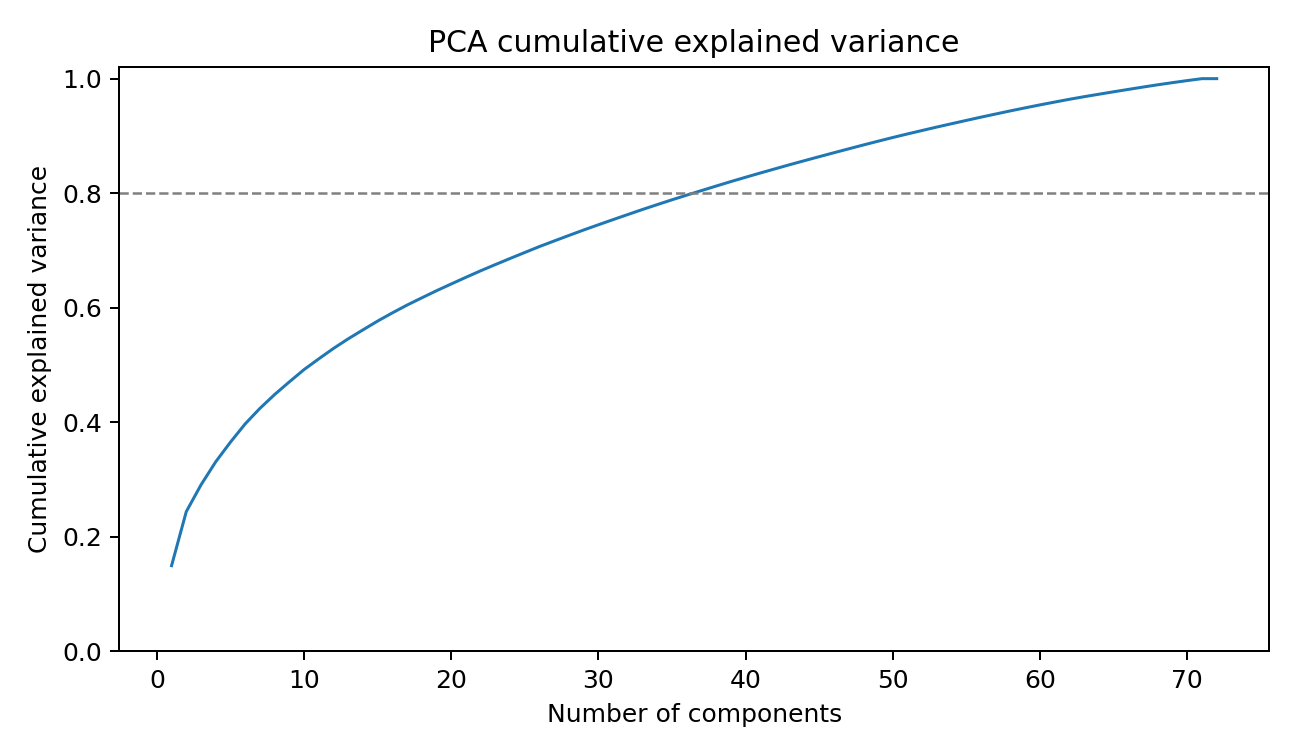

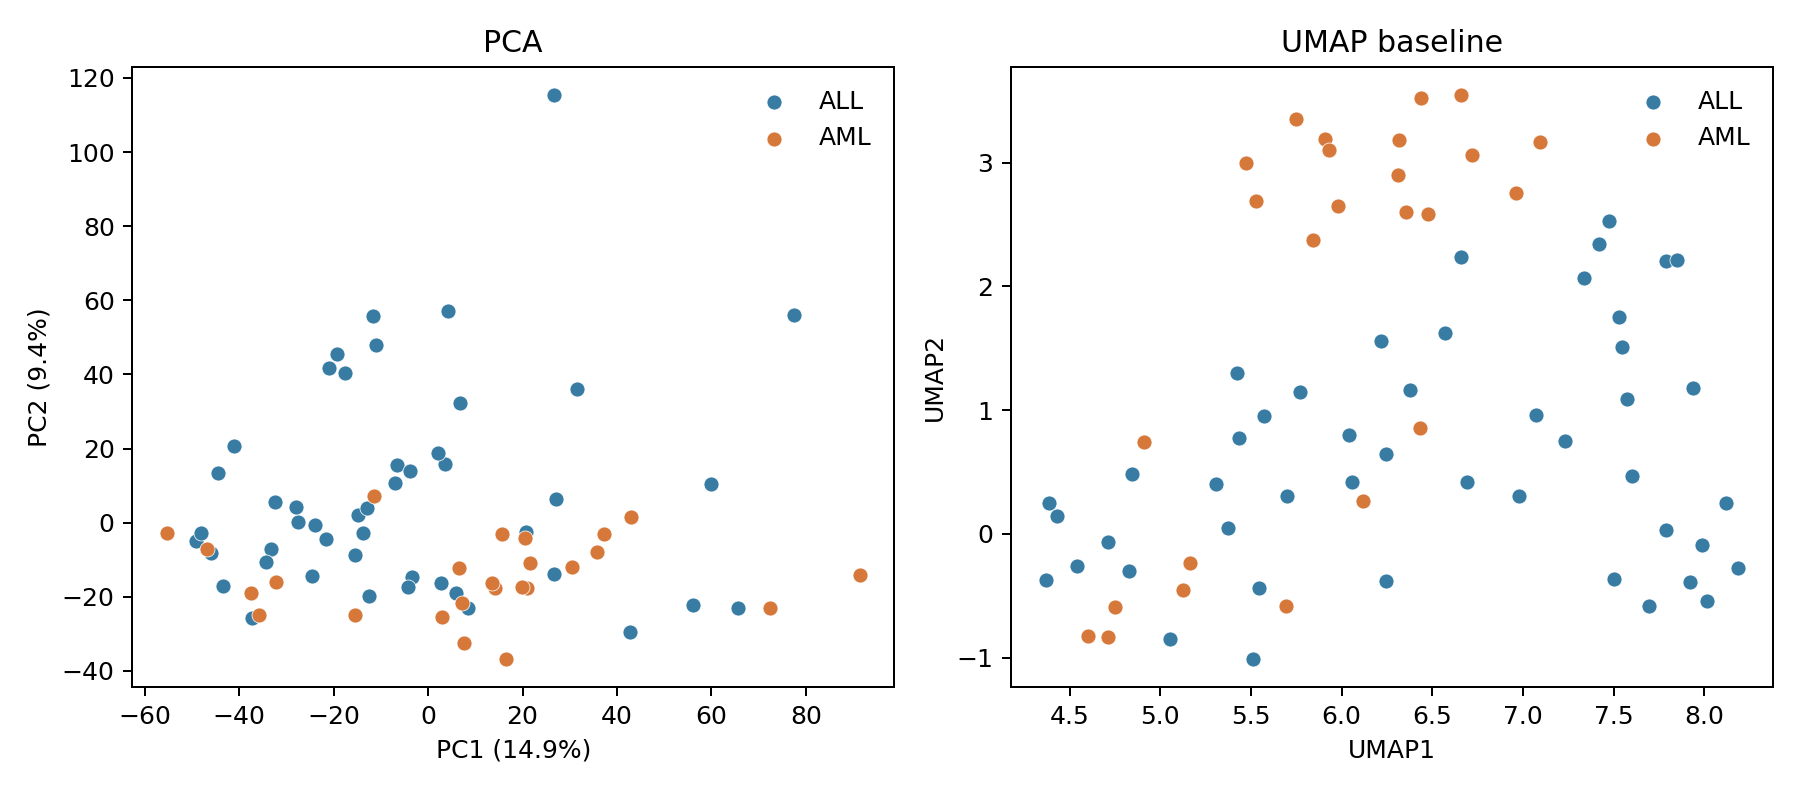

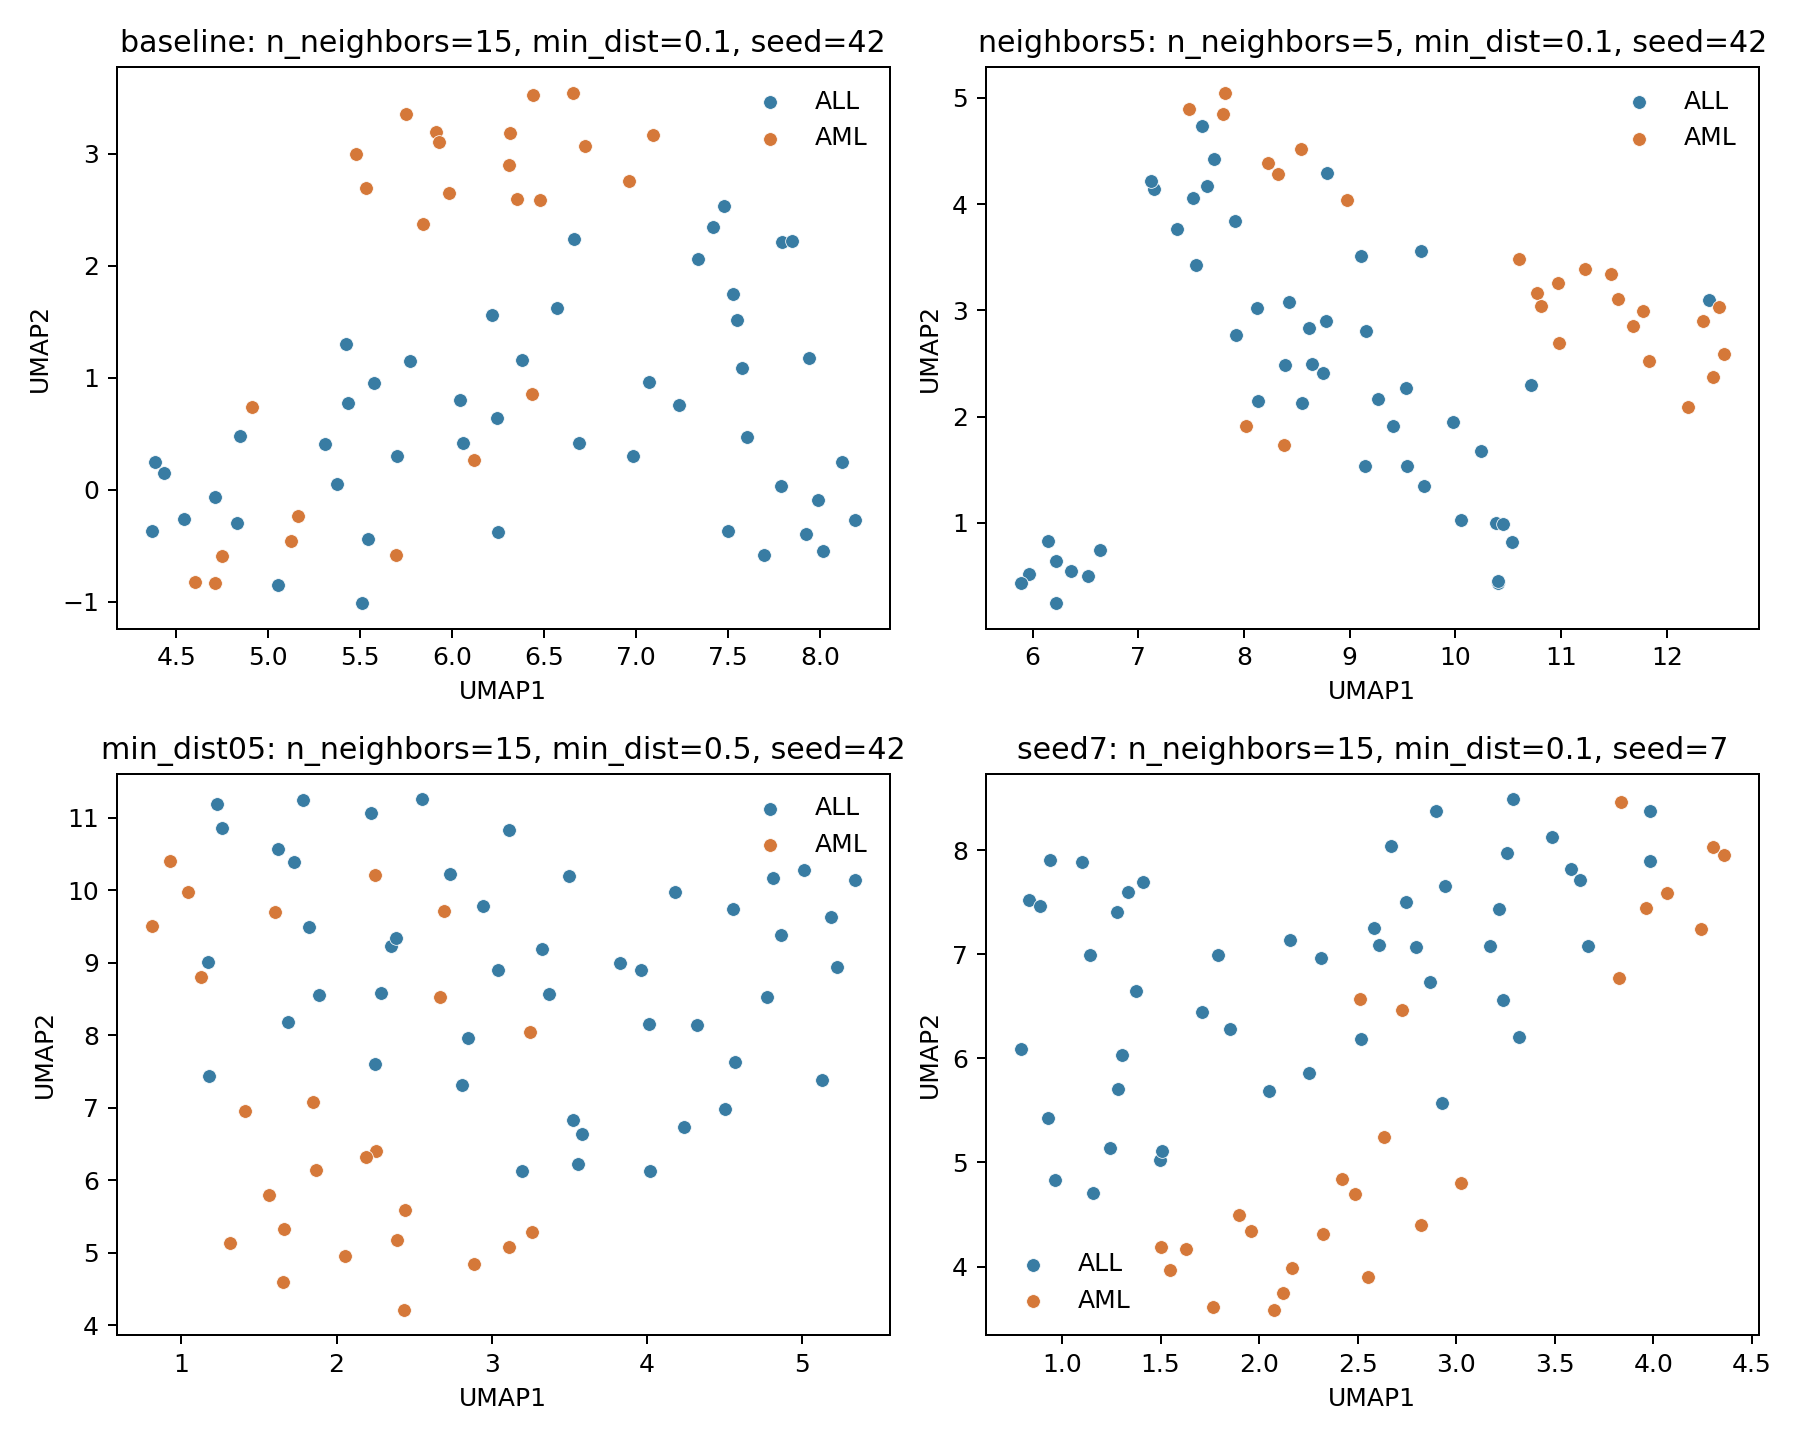

,setting,mean_10_neighbor_overlap_vs_baseline,spearman_pairwise_distance_vs_baseline,trustworthiness_k10
0,baseline,1.000000,1.000000,0.793142
1,neighbors5,0.620833,0.839749,0.778269
2,min_dist05,0.676389,0.865659,0.796264
3,seed7,0.676389,0.880518,0.794371


In [3]:
from IPython.display import display, Image
import importlib.metadata as metadata
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'umap-learn', 'numba', 'llvmlite', 'pynndescent', 'threadpoolctl', 'nbformat', 'nbclient']:
    print(package, metadata.version(package))
for filename in ['pca-standardized.png', 'pca-cumulative-variance.png', 'pca-umap-baseline.png', 'umap-parameter-checks.png']:
    display(Image(filename=str(OUT / filename)))
display(pd.read_csv(OUT / 'umap-stability.csv'))


## 样本追踪与稳定近邻

完整坐标按教学编号G001—G072对应；诊断仅事后标注。最近邻集在各二维布局计算，不可当作原始高维真实生物关系。

In [4]:
coords = pd.read_csv(OUT / 'umap-sample-coordinates.csv')
pca_coords = pd.read_csv(OUT / 'pca-sample-coordinates.csv')
wide = coords.pivot(index='sample_id', columns='setting', values=['UMAP1', 'UMAP2'])
wide.columns = ['_'.join(c) for c in wide.columns]
tracking = pca_coords.merge(wide, on='sample_id', validate='one_to_one')
assert tracking.shape[0] == 72 and not tracking.isna().any().any()
print(tracking.to_string(index=False))
sets = {}
for setting, group in coords.groupby('setting', sort=False):
    group = group.sort_values('sample_id')
    values = group[['UMAP1','UMAP2']].to_numpy()
    ids = group.sample_id.to_numpy()
    nn = NearestNeighbors(n_neighbors=11).fit(values).kneighbors(values, return_distance=False)
    sets[setting] = [set(ids[row[1:]]) for row in nn]
for index in [0, 9, 37, 71]:
    stable = set.intersection(*(neighbors[index] for neighbors in sets.values()))
    print(f'G{index+1:03d} 四种布局共有的10近邻:', ', '.join(sorted(stable)) or '无')


sample_id diagnosis        PC1        PC2  UMAP1_baseline  UMAP1_min_dist05  UMAP1_neighbors5  UMAP1_seed7  UMAP2_baseline  UMAP2_min_dist05  UMAP2_neighbors5  UMAP2_seed7
     G001       ALL  27.105207   6.448490        7.527618          4.242845         10.055384     0.928812        1.749259          6.732675          1.022409     5.430337
     G002       ALL   3.507419  15.845801        7.233461          4.321175          9.536812     1.712362        0.753453          8.143794          2.273381     6.443752
     G003       ALL  60.006379  10.392307        7.544736          4.501159          9.701388     1.285627        1.512743          6.984841          1.346992     5.706972
     G004       ALL  20.640386  -2.623372        7.338019          4.019698         10.379709     1.241458        2.063425          6.123560          0.996700     5.141459
     G005       ALL -21.012018  41.794160        7.786791          4.863666          6.518684     1.409877        0.032986          9.381099